<a href="https://colab.research.google.com/github/suzzette211/AI-For-Science-and-Engineering/blob/main/Week_4_Assignment_%7C_Exploring_the_Mathematics_of_Your_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Descriptive Statistics and Correlation:Concrete Strength **

### 1. **Project problem and Intended outcome**

Concrete compressive strength is an important engineering property used when designing and assessing concrete structures. It depends on several factors, including cement content, water content, aggregate proportions, supplementary cementitious materials, and the age of the concrete when tested.

This project will explore conncrete-stength datasets to understand the relationship between cement content and compressive strength.

## **2. Datasets**

dataset: concrete compressive strength dataset from Kaggle

The data needed for this analysis include:

*   Cement: Cement content in kg/m³.

*   Water: Water content in kg/m³.


*   Age: Concrete age at testing in days.
*  Concrete compressive strength: Measured compressive strength in MPa.





**a) Importing the dataset from kaggle**

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("elikplim/concrete-compressive-strength-data-set")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'concrete-compressive-strength-data-set' dataset.
Path to dataset files: /kaggle/input/concrete-compressive-strength-data-set


In [6]:
import os
import pandas as pd

# See which files were downloaded
print(os.listdir(path))

# Load the CSV (use the filename printed above)
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

# Display the first 5 samples
df.head()

['concrete_data.csv']


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


**b) sample of my project features from the dataset**

In [8]:
import pandas as pd

def find_col(keyword):
    return [c for c in df.columns if keyword.lower() in c.lower()][0]

cols = [find_col("cement"), find_col("water"), find_col("age"), find_col("compressive")]
df_sel = df[cols]

df_sel.sample(5, random_state=42)

,cement,water,age,concrete_compressive_strength
31,266.0,228.0,365,52.91
109,362.6,164.9,7,55.90
136,389.9,145.9,28,74.50
88,362.6,164.9,3,35.30
918,145.0,202.0,28,10.54


## **3. Mean, median, range, variance, standard deviation**

In [10]:
stats = pd.DataFrame({
    "Mean": df_sel.mean(),
    "Median": df_sel.median(),
    "Range": df_sel.max() - df_sel.min(),
    "Variance": df_sel.var(),
    "Std Dev": df_sel.std()
})
stats.round(2)

,Mean,Median,Range,Variance,Std Dev
cement,281.17,272.90,438.00,10921.58,104.51
water,181.57,185.00,125.20,456.00,21.35
age,45.66,28.00,364.00,3990.44,63.17
concrete_compressive_strength,35.82,34.44,80.27,279.08,16.71


## **4.Covariance and correlation( cement vs. strength)**

In [11]:
x = df_sel[cols[0]]   # cement (input)
y = df_sel[cols[3]]   # compressive strength (output)

cov = x.cov(y)
corr = x.corr(y)

print(f"Covariance: {cov:.2f}")
print(f"Correlation: {corr:.2f}")

Covariance: 869.14
Correlation: 0.50


## **5.Plot**

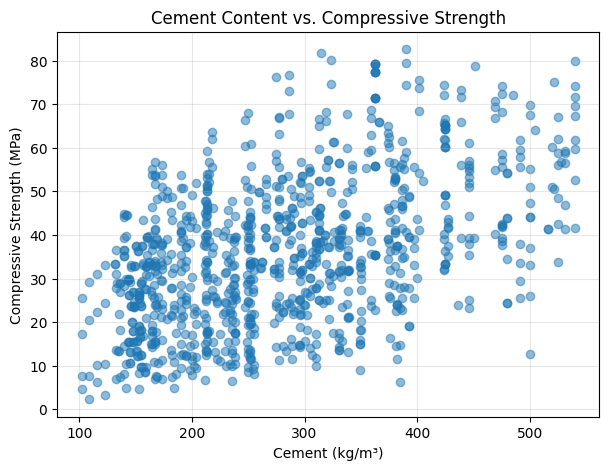

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Cement (kg/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Cement Content vs. Compressive Strength")
plt.grid(True, alpha=0.3)
plt.show()

## **6. Input -> Model -> Output**

In [13]:
import numpy as np

# Fit a simple line: strength = b0 + b1 * cement
b1, b0 = np.polyfit(x, y, 1)
print(f"strength = {b0:.2f} + {b1:.3f} * cement")

# Example: predict strength for a mix with 300 kg/m³ of cement
print("Predicted strength:", b0 + b1 * 300)

strength = 13.44 + 0.080 * cement
Predicted strength: 37.3166288664615


# **7. Conclusion**

The mean and median of each variable are close/different (state which), which suggests
the distributions are roughly symmetric/skewed. Age has a large range and variance
compared with its mean, meaning most samples were tested at early ages while a few were
tested much later. Strength has a standard deviation of about 16.71 MPa, so mixes vary a lot
in how strong they end up.

The correlation between cement and strength is about strength = 13.44 + 0.080 * cement. It is
positive and moderate, so mixes with more cement tend to have higher compressive
strength. It is not close to 1, so cement alone doesn't explain strength; water, age and
other ingredients also matter.

Correlation only shows that two variables move together. Other factors could drive
both, such as mixes with more cement also having less water or different aggregates.
Establishing causation would require controlled experiments or more careful analysis.